In [1]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image
import keras

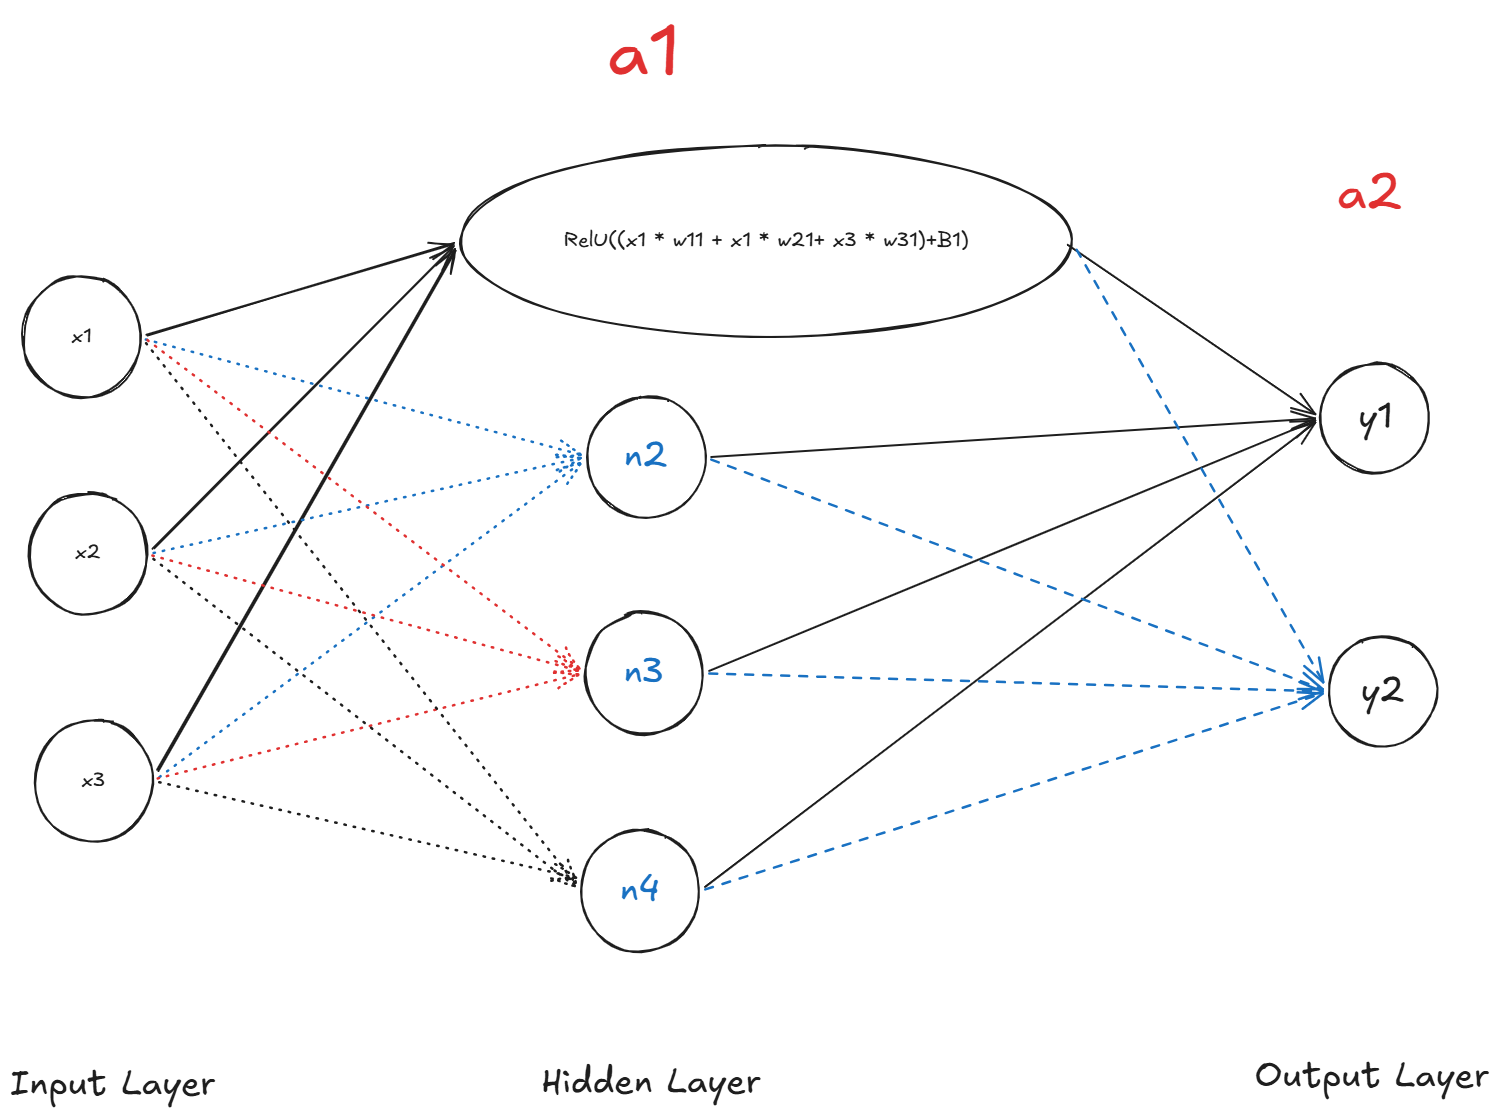

In [2]:
# IMPORTS FOR IMAGES
display(Image(filename="assets/nn.png"))

# Building a Neural Network From Scratch — With Mathematics and NumPy

There is something truly beautiful about building something intelligent from simple mathematical principles. Inspired by the way biological neurons communicate and form connections, artificial neural networks use layers of mathematical operations to learn patterns, recognize relationships, and make predictions. What makes this fascinating is that we can build one from scratch, using mathematics, calculus, linear algebra, and NumPy.

The central idea behind this project is surprisingly simple: **start with a mathematical function, measure how wrong its predictions are, and gradually adjust its parameters to minimize the error.**

## 1. The Mathematical Foundation

Our neural network transforms input data through a sequence of mathematical operations:

$$
\hat{Y} = \operatorname{Softmax}\left(
\operatorname{ReLU}(XW^{(1)} + b^{(1)})W^{(2)} + b^{(2)}
\right)
$$

Here, $X$ represents the input data, $W^{(1)}$ and $W^{(2)}$ are the weight matrices, and $b^{(1)}$ and $b^{(2)}$ are the bias vectors. ReLU introduces nonlinearity, allowing the network to learn complex patterns, while Softmax converts the final outputs into class probabilities.

## 2. Measuring the Error: The Loss Function

How do we know whether the network is making good predictions? We compare its predictions, $\hat{Y}$, with the true labels, $Y$, using a loss function.

For multiclass classification, we use **categorical cross-entropy**:

$$
\mathcal{L}(\hat{Y},Y)
=
-\frac{1}{m}
\sum_{i=1}^{m}
\sum_{c=1}^{C}
Y_{ic}\log(\hat{Y}_{ic})
$$

where:

- $m$ is the number of training samples.
- $C$ is the number of classes.
- $Y_{ic}$ is the true label for sample $i$ and class $c$.
- $\hat{Y}_{ic}$ is the predicted probability for sample $i$ belonging to class $c$.

The loss quantifies how far the predictions are from the correct answers. Our objective is to **minimize this loss as much as possible**, encouraging the network to make increasingly accurate predictions.

## 3. Learning Through Backpropagation and Gradient Descent

This is where the mathematics becomes truly powerful. Through *backpropagation* and the chain rule, we calculate how each weight and bias contributes to the loss.

We then use gradient descent to update the parameters in the direction that reduces the loss:

$$
\theta \leftarrow \theta -
\alpha \frac{\partial \mathcal{L}}{\partial \theta}
$$

Here, $\theta$ represents a trainable parameter, $\alpha$ is the learning rate, and $\frac{\partial \mathcal{L}}{\partial \theta}$ is the gradient of the loss with respect to that parameter.

By repeating this process over many iterations, the network gradually adjusts its weights and biases to learn patterns from the training data.

## 4. The Objective of This Project

The goal of this notebook is not simply to use a prebuilt machine learning library and obtain a prediction. Instead, it is to understand what happens beneath the surface:

- How matrices represent layers of artificial neurons.
- How activation functions introduce nonlinearity.
- How derivatives carry learning signals backward through the network.
- How gradient descent updates parameters to reduce the loss.
- How a mathematical model learns patterns from data and makes predictions.

**No TensorFlow. No PyTorch. No prebuilt training engine. Just Python, NumPy, linear algebra, calculus, and the mathematics of learning.**

By implementing each component ourselves, from the forward pass to backpropagation and parameter updates, we move beyond treating neural networks as black boxes and begin to understand why they work.

*The real beauty of deep learning lies not only in the predictions a model makes, but in discovering how simple mathematical rules, repeated and refined, can give rise to the ability to learn.*


#### Example with numpy on a single neuron (the sum weights function)

In [3]:
X = np.random.randn(1,3)
W = np.random.randn(3,5)
B = np.zeros((1,5))

In [4]:
X

array([[ 0.40456042, -2.74448269,  1.64303984]])

In [5]:
W

array([[ 2.43425409,  0.11635728,  1.69729646,  0.48112457, -0.46383016],
       [-0.27175274,  1.89154579,  0.25400425, -1.74591062,  1.11730743],
       [-1.77339817,  0.34135272,  0.12133047,  0.39823177,  0.61012481]])

In [6]:
B

array([[0., 0., 0., 0., 0.]])

In [7]:
np.dot(X, W)

array([[-1.1831403 , -4.58338501,  0.18889949,  5.64057608, -2.25161885]])

In [8]:
np.dot(X, W) + B

array([[-1.1831403 , -4.58338501,  0.18889949,  5.64057608, -2.25161885]])

#### Get Mnist dataset

In [9]:
(x_train, y_train), (x_test, y_test) = (
    keras.datasets.mnist.load_data()
)

print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", x_test.shape)
print("Testing labels:", y_test.shape)

Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


#### Create the neural network model

In [10]:
class NeuralNetwork:
    '''
        X : the input Layer
        Y : the output Layer
        inputs : number of values on a sequence of a batch for the inputs layer
        outputs : the number of neurons on the output layer
        hlayer_d : the number of neuron on the hidden layer
    '''
    def __init__(self, X ,Y, inputs, outputs,hlayer_d):
        self.outputs = outputs
        self.X , self.Y= X, Y
        self.w1 = np.random.randn(inputs, hlayer_d) * np.sqrt(2.0 / inputs)
        self.w2 = np.random.randn(hlayer_d, outputs) * np.sqrt(2.0 / (hlayer_d + outputs))
        self.b1 = np.zeros((1,hlayer_d))
        self.b2 = np.zeros((1,outputs))

    def forward(self, x):
        self.z1 = np.dot(x, self.w1) + self.b1
        self.a1 = self.Relu(self.z1)
        self.z2 = np.dot(self.a1, self.w2) + self.b2
        self.a2 = self.softmax(self.z2)
   

   
    
    def backward(self, alpha):
        #calculate the gradients 
        m = self.X.shape[1]
        one_hot_Y = self.one_hot(self.Y)
        
        dZ2 = self.a2 - one_hot_Y

        dW2 = (self.a1.T @ dZ2) / m
        db2 = np.sum(dZ2, axis=0, keepdims=True) / m

        # Hidden layer gradients
        dZ1 = (dZ2 @ self.w2.T) * self.Relu(self.z1, deriv=True)

        dW1 = (self.X.T @ dZ1) / m
        db1 = np.sum(dZ1, axis=0, keepdims=True) 

        # update paramters
        
        self.w1 = self.w1 - alpha * dW1
        self.b1 = self.b1 - alpha * db1    
        self.w2 = self.w2 - alpha * dW2  
        self.b2 = self.b2 - alpha * db2  


    def train(self, epochs=10, alpha=0.01, batch_size=128):
        losses = []
        accuracies = []
    
        X, Y = self.X, self.Y
        m = len(X)
    
        for epoch in range(epochs):
            for i in range(0, m, batch_size):
                self.X = X[i:i + batch_size]
                self.Y = Y[i:i + batch_size]
    
                self.forward(self.X)
                
                '''print(self.X)
                print("============ WEIGHTS ===========")
                print(self.w1)
                print(self.b1)
                print("========= Hidden LAYER =======")
                print(self.a1)
                print("============ WEIGHTS ===========")
                print(self.w2)
                print(self.b2)
                print("========= OUTPUT LAYER =======")
                print(self.a2)'''
                
                self.backward(alpha)
    
            # restore values to calulate loss and accuracy
            self.X, self.Y = X, Y
            self.forward(self.X)
    
            loss = self.loss()
            accuracy = self.get_accuracy(self.get_predictions(self.a2)) * 100
    
            losses.append(loss)
            accuracies.append(accuracy)
    
            print(
                f"Epoch {epoch + 1}/{epochs} | "
                f"Loss: {loss:.4f} | "
                f"Accuracy: {accuracy:.2f}%"
            )
    
        
        fig, ax = plt.subplots(1, 2, figsize=(12, 4))
        # loss graph
        
        ax[0].plot(losses)
        ax[0].set_title("Training Loss")
        ax[0].set_xlabel("Epoch")
        ax[0].set_ylabel("Loss")
        
        # Accuracy graph
        ax[1].plot(accuracies)
        ax[1].set_title("Training Accuracy")
        ax[1].set_xlabel("Epoch")
        ax[1].set_ylabel("Accuracy (%)")
    
        plt.tight_layout()
        plt.show()
    
   

    def fit(self, image):
        self.forward(image)
        pred = self.get_predictions(self.a2)
        print("predictions:", pred)
        return pred



    def Relu(self, A, deriv=False):
        if deriv:
            return (A > 0).astype(float)
    
        return np.maximum(0, A)
    

    def softmax(self, Z):
        Z = Z - np.max(Z, axis=1, keepdims=True)
        exp_Z = np.exp(Z)
        return exp_Z / np.sum(exp_Z, axis=1, keepdims=True)

    
    def one_hot(self, Y):
        Y = np.asarray(Y).reshape(-1).astype(int)
    
        one_hot_Y = np.zeros((Y.size, self.outputs))
        one_hot_Y[np.arange(Y.size), Y] = 1
    
        return one_hot_Y
    
    
    def loss(self):
        m = self.Y.size
    
        one_hot_Y = self.one_hot(self.Y)
        probabilities = np.clip(self.a2, 1e-12, 1.0)
    
        return -np.sum(one_hot_Y * np.log(probabilities)) / m
    
    
    def get_predictions(self, a2):
        return np.argmax(a2, axis=1)
    
    
    def get_accuracy(self, predictions):
        predictions = np.asarray(predictions).reshape(-1)
        Y = np.asarray(self.Y).reshape(-1)
    
        return round(np.mean(predictions == Y), 4)

# Train the NN With MNIST data to predict drawing numbers

Epoch 1/30 | Loss: 2.0256 | Accuracy: 33.56%
Epoch 2/30 | Loss: 1.8154 | Accuracy: 43.16%
Epoch 3/30 | Loss: 1.5964 | Accuracy: 53.42%
Epoch 4/30 | Loss: 1.4001 | Accuracy: 64.25%
Epoch 5/30 | Loss: 1.2302 | Accuracy: 69.76%
Epoch 6/30 | Loss: 1.0866 | Accuracy: 73.34%
Epoch 7/30 | Loss: 0.9714 | Accuracy: 75.80%
Epoch 8/30 | Loss: 0.8819 | Accuracy: 77.50%
Epoch 9/30 | Loss: 0.8127 | Accuracy: 78.74%
Epoch 10/30 | Loss: 0.7585 | Accuracy: 79.81%
Epoch 11/30 | Loss: 0.7153 | Accuracy: 80.71%
Epoch 12/30 | Loss: 0.6800 | Accuracy: 81.40%
Epoch 13/30 | Loss: 0.6505 | Accuracy: 82.10%
Epoch 14/30 | Loss: 0.6255 | Accuracy: 82.67%
Epoch 15/30 | Loss: 0.6039 | Accuracy: 83.13%
Epoch 16/30 | Loss: 0.5851 | Accuracy: 83.60%
Epoch 17/30 | Loss: 0.5685 | Accuracy: 84.04%
Epoch 18/30 | Loss: 0.5538 | Accuracy: 84.39%
Epoch 19/30 | Loss: 0.5407 | Accuracy: 84.71%
Epoch 20/30 | Loss: 0.5288 | Accuracy: 85.06%
Epoch 21/30 | Loss: 0.5182 | Accuracy: 85.36%
Epoch 22/30 | Loss: 0.5085 | Accuracy: 85.6

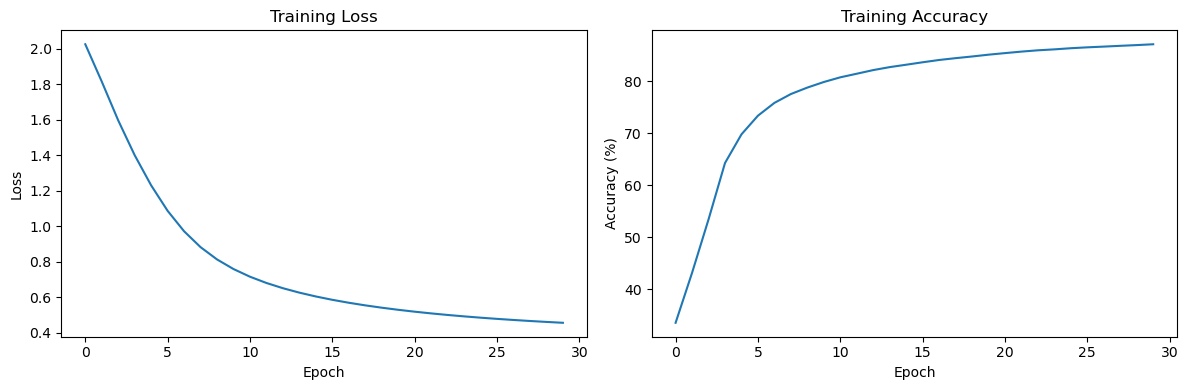

In [11]:
X_train = x_train.reshape(-1, 784).astype(np.float32) / 255.0
X_test = x_test.reshape(-1, 784).astype(np.float32) / 255.0

nn = NeuralNetwork(
    X=X_train,
    Y=y_train,       
    inputs=784,
    outputs=10,
    hlayer_d=10
)

nn.train(epochs=30, alpha=0.01, batch_size=128)

# Test NN


i tested it on the first 10 images and this is what i got

PREDICTION NUMBER 1
predictions: [7]


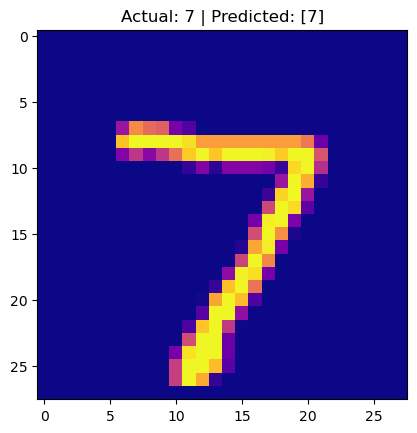

PREDICTION NUMBER 2
predictions: [2]


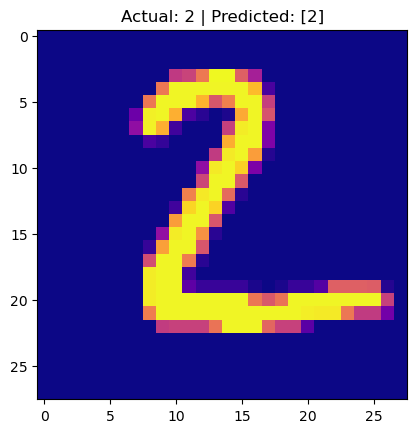

PREDICTION NUMBER 3
predictions: [1]


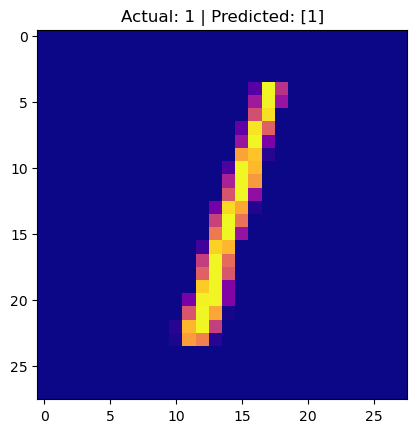

PREDICTION NUMBER 4
predictions: [0]


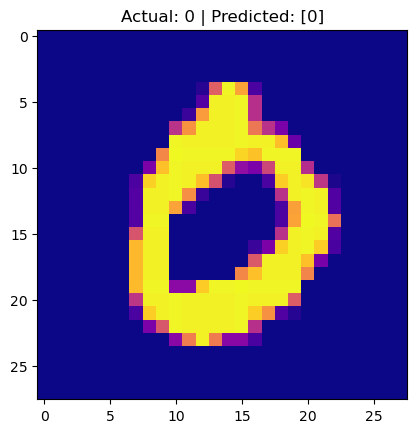

PREDICTION NUMBER 5
predictions: [4]


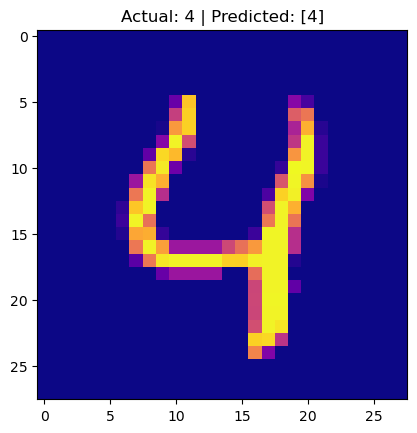

PREDICTION NUMBER 6
predictions: [1]


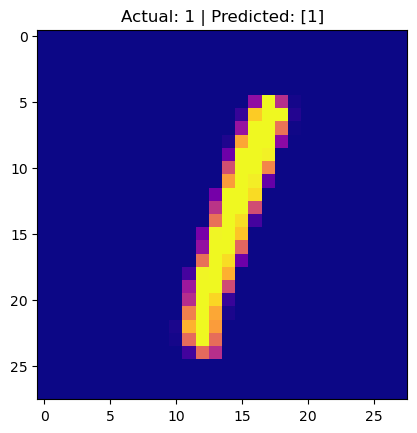

PREDICTION NUMBER 7
predictions: [4]


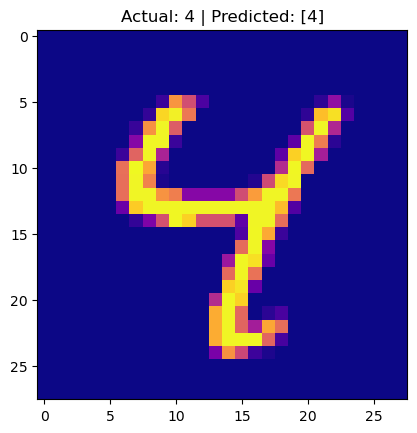

PREDICTION NUMBER 8
predictions: [9]


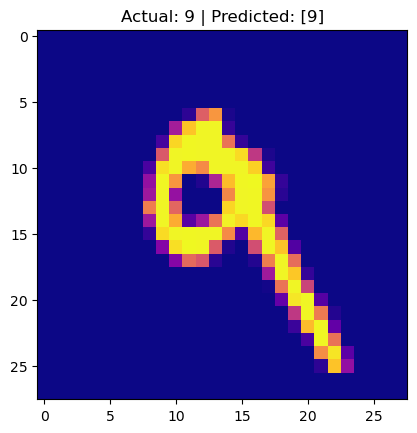

PREDICTION NUMBER 9
predictions: [6]


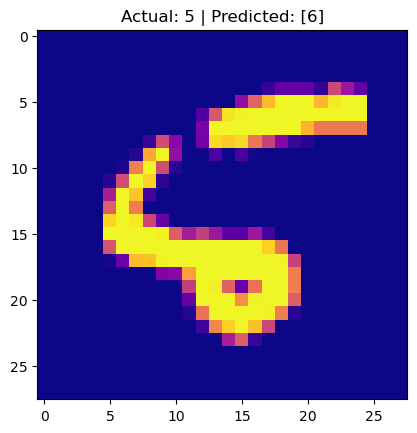

PREDICTION NUMBER 10
predictions: [9]


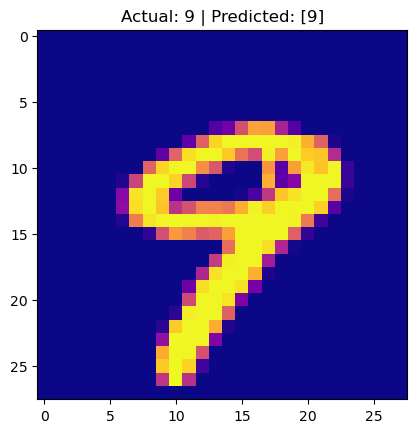

In [12]:
for i in range(0, 10):
    print(f"PREDICTION NUMBER {i + 1}")
    pred = nn.fit(X_test[i])
    plt.imshow(x_test[i], cmap="plasma")
    plt.title(
        f"Actual: {y_test[i]} | Predicted: {pred}"
    )

    plt.show()

# accuracy for all the testing data 

In [13]:
predictions = nn.fit(X_test)

predictions: [7 2 1 ... 4 5 6]


In [14]:
nn.Y = y_test
print(f"acc {nn.get_accuracy(predictions)*100:.2f} %")

acc 87.35 %
